In [99]:
%pip -q install ISLP

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text



In [101]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [102]:
hitters = hitters.dropna(subset=['Salary']).copy()

X = hitters.drop(columns='Salary')
y = hitters['Salary']

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)


In [103]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = []


In [104]:
alpha_examples = [ 0.1, 10, 100]
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:

    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        coefs = pipe.named_steps['model'].coef_


        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Test RMSE,Training RMSE
0,Lasso,0.1,19,356.83,289.38
1,Lasso,10.0,9,381.84,303.10
2,Lasso,100.0,5,395.12,341.39


Questions:
1. As α increases, what happens to the number of retained predictors?

As α increases the number of retaind predictors decreases

2. Does a smaller number of predictors always lead to a lower test RMSE?

No

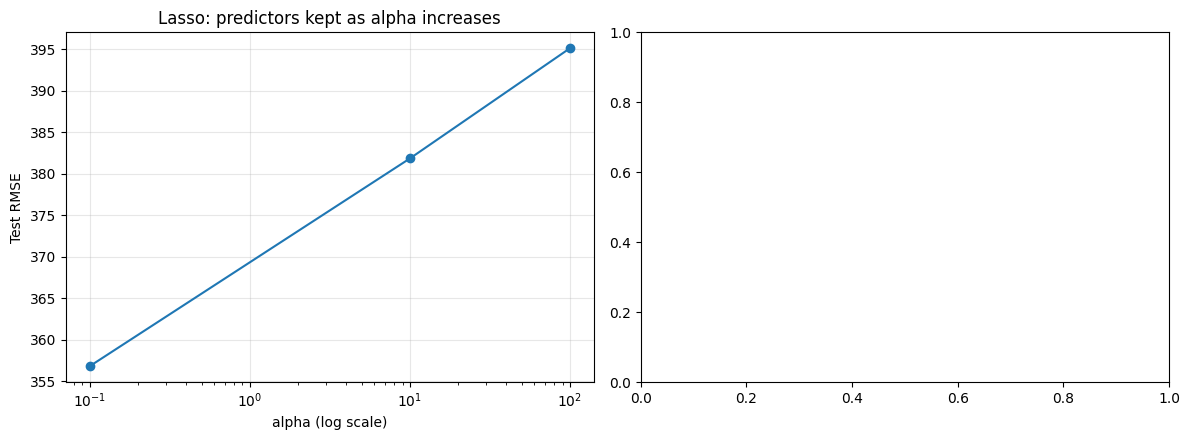

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, kind in zip(axes, ['Lasso']):
    subset = alpha_table[alpha_table['Model'] == kind]
    ax.semilogx(subset['alpha'], subset['Test RMSE'], marker='o')
    ax.set_title(f'{kind}: predictors kept as alpha increases')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('Test RMSE')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Questions:
1. Which α produces the lowest test RMSE among the three values?
0.1

2. Which α appears to cause the most underfitting? Explain using bias.

100 has the highest errors and fewest non zero coeficients making it simpler and more biased than the other values.

3. Why might a model with higher training RMSE produce lower test RMSE

a model with hihgher training RMSE might have a lower test RMSE if there is more noise in the training set


In [109]:
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': pipe.named_steps['model'].coef_,
})

display(coef_table.round(2))

,Feature,OLS
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


1. Identify two predictors that Lasso sets to zero at α = 100.

num__HmRun and num__Runs

2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.

No, could mean there are multiple corelated predictors so lasso keeps one and sets rest to 0.


3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.


One with fewer predictors because its less likely to overfit and would probably generalize better to new data.

 Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.

Lasso because there is a lot of messurments and the goal is to identify a **small** number of mesurments may be usefull to predict disease severity. Lasso will reduce the number of mesurments used to predict disease severity by turning many corelated mesurments to 0.


- Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

probably ridge or lasso because many of the predictors are strongly related and they belive most contain useful information, lasso would over look a lot of those predictors by reducing them to 0 but they did say "Keeping all predictors is not a concern" so it would help to know what those predictors are to make a desision. linier regression would not work well with the stronlgy corelated predictors.

- Scenario C: A researcher has 10,000 observations and only three predictors. The relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

linear regression because it has 3 predictors, appers approximatly linear, and they want a simple model.

- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.

lasso or ridge, lasso would help with lowering correlated predictors if they are not usefull but ridge would be better if there are corelatod predictors that are still useful.

